# Brain MRI Tumor Classification

## Notebook 2 — Custom CNN Training and Evaluation


## Notebook Overview

In this notebook, we train a custom convolutional neural network (CNN) to classify brain MRI images into **Glioma, Meningioma, No Tumor, and Pituitary**. We use the verified manifest created in Notebook 1, train only on the training split, and use the validation split to monitor learning, continue training at a lower learning rate if useful, and select the best checkpoint.

The test split is held aside until all training and selection decisions are complete. We use it once for the final evaluation. The selected model and its label/configuration files are saved to a `models` folder in Google Drive.

**Use limitation:** this is an educational machine-learning exercise. Predictions and confidence scores are not medical diagnoses or clinical recommendations.


## Notebook Plan

1. Connect Google Drive and locate Notebook 1's verified manifest.
2. Load the manifest and separate train, validation, and test rows.
3. Build TensorFlow input pipelines for train and validation only. Keep test data aside.
4. Define a custom CNN, its loss, optimizer, metrics, and class weights.
5. Train the CNN and save the best validation-loss checkpoint.
6. Review learning curves and validation metrics.
7. Continue training from the best checkpoint at a lower learning rate, then choose between checkpoints using validation loss.
8. Evaluate the chosen checkpoint once on the held-out test split.
9. Save the final model, class names, and evaluation summary.


## Step 1 — Connect Drive and set project paths

Mount Google Drive in Colab. Set `DATASET_ROOT` to the folder that directly contains `train`, `valid`, and `test`. Notebook 1 saves the verified manifest in a sibling folder named `notebook_outputs`. This notebook will save model files in a sibling folder named `models`.

Update the placeholder path before running the cell. It should be the same `Datasets` folder used in Notebook 1.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

DATASET_ROOT = Path('/content/drive/MyDrive/Brain MRI Tumor Classification/Datasets')
PROJECT_ROOT = DATASET_ROOT.parent
MANIFEST_PATH = DATASET_ROOT / 'brain_mri_dataset_manifest.csv'
MODEL_DIR = PROJECT_ROOT / 'Models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)


IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
FINE_TUNE_EPOCHS = 8
SEED = 42
CLASS_NAMES = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
NUM_CLASSES = len(CLASS_NAMES)

tf.keras.utils.set_random_seed(SEED)
print('TensorFlow version:', tf.__version__)
print('Dataset folder:', DATASET_ROOT)
print('Manifest:', MANIFEST_PATH)
print('Model output folder:', MODEL_DIR)
print('GPU devices:', tf.config.list_physical_devices('GPU'))

if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        f'Manifest not found: {MANIFEST_PATH}. Run Notebook 1 first and check the Drive path.'
    )


TensorFlow version: 2.21.0
Dataset folder: /content/drive/MyDrive/Brain MRI Tumor Classification/Datasets
Manifest: /content/drive/MyDrive/Brain MRI Tumor Classification/Datasets/brain_mri_dataset_manifest.csv
Model output folder: /content/drive/MyDrive/Brain MRI Tumor Classification/Models
GPU devices: []


## Step 2 — Load and separate the verified manifest

The manifest has one row per CSV image entry. Here we keep only rows that passed Notebook 1's checks and have an image path and label. We create separate tables for train, validation, and test. The test table is only stored for now; it will not be loaded into a model pipeline until the final evaluation step.


In [ ]:
manifest = pd.read_csv(MANIFEST_PATH)
required = {'filepath', 'split', 'label', 'label_verified'}
missing = required - set(manifest.columns)
if missing:
    raise ValueError(f'Manifest is missing required columns: {sorted(missing)}')

manifest['filepath'] = manifest['filepath'].astype('string').str.strip()
manifest['label'] = manifest['label'].astype('string').str.strip()
verified = manifest[
    manifest['label_verified'].astype(str).str.lower().isin(['true', '1'])
    & manifest['filepath'].notna()
    & manifest['label'].notna()
].copy()

unknown_labels = sorted(set(verified['label']) - set(CLASS_NAMES))
if unknown_labels:
    raise ValueError(f'Unexpected labels in manifest: {unknown_labels}')

train_df = verified[verified['split'] == 'train'].copy()
valid_df = verified[verified['split'] == 'valid'].copy()
test_df = verified[verified['split'] == 'test'].copy()
if train_df.empty or valid_df.empty or test_df.empty:
    raise ValueError('Train, valid, and test splits must all have verified rows.')

for name, frame in [('train', train_df), ('valid', valid_df), ('test (held aside)', test_df)]:
    print(f'{name}: {len(frame):,} images')
print('\nTraining class counts:')
display(train_df['label'].value_counts().reindex(CLASS_NAMES, fill_value=0).rename('images'))


train: 1,695 images
valid: 502 images
test (held aside): 246 images

Training class counts:


,images
label,
Glioma,564
Meningioma,358
No Tumor,335
Pituitary,438


## Step 3 — Create image pipelines for training and validation

Images will be decoded as RGB and resized to 224 × 224 pixels, which gives the CNN a consistent input shape. Pixel values are kept in the 0–255 range here; a `Rescaling` layer inside the model will convert them to 0–1. We create datasets for train and validation only.

The input pipeline reads images in batches instead of loading the whole image collection into memory.


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
LABEL_TO_ID = {name: index for index, name in enumerate(CLASS_NAMES)}

def make_dataset(frame, training=False):
    paths = frame['filepath'].astype(str).to_numpy()
    labels = frame['label'].map(LABEL_TO_ID).to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_and_resize(path, label):
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMAGE_SIZE)
        return image, label

    if training:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(load_and_resize, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
valid_ds = make_dataset(valid_df, training=False)
print('Training and validation pipelines are ready.')


Training and validation pipelines are ready.


## Step 4 — Define the custom CNN

The model uses three convolution blocks to learn image features, followed by a compact dense classifier with four outputs. Batch normalization and dropout help control overfitting. Mild rotation and zoom augmentation are placed in the model; Keras applies these random transformations during training and disables them during validation and prediction.

The class order is fixed as `Glioma`, `Meningioma`, `No Tumor`, `Pituitary`, so the output index remains interpretable.


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03, seed=SEED),
    tf.keras.layers.RandomZoom(0.05, seed=SEED),
], name='training_augmentation')

def build_custom_cnn():
    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3), name='mri_image')
    x = tf.keras.layers.Rescaling(1.0 / 255.0, name='pixel_rescaling')(inputs)
    x = data_augmentation(x)

    for filters in (32, 64, 128):
        x = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation('relu')(x)
        x = tf.keras.layers.MaxPooling2D()(x)
        x = tf.keras.layers.Dropout(0.20)(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.35)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='class_probabilities')(x)
    return tf.keras.Model(inputs, outputs, name='brain_mri_custom_cnn')

model = build_custom_cnn()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
model.summary()


Model: "brain_mri_custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mri_image (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pixel_rescaling (Rescaling)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 110,948 (433.39 KB)

 Trainable params: 110,500 (431.64 KB)

 Non-trainable params: 448 (1.75 KB)

## Step 5 — Calculate class weights and train

The training classes have different image counts. Class weights give the less frequent classes more influence during loss calculation. The model is trained using train images; validation images monitor progress. The best checkpoint is saved according to validation loss, and early stopping ends training if validation loss no longer improves.


In [11]:
train_counts = train_df['label'].value_counts().reindex(CLASS_NAMES, fill_value=0)
if (train_counts == 0).any():
    raise ValueError(f'At least one class has no training images: {train_counts.to_dict()}')
class_weights = {
    LABEL_TO_ID[label]: float(len(train_df) / (NUM_CLASSES * train_counts[label]))
    for label in CLASS_NAMES
}
print('Training counts:', train_counts.to_dict())
print('Class weights:', class_weights)

initial_checkpoint = MODEL_DIR / 'custom_cnn_best_validation.keras'
initial_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        initial_checkpoint, monitor='val_loss', mode='min', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', mode='min', patience=5, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', mode='min', factor=0.3, patience=2, min_lr=1e-6, verbose=1
    ),
]

initial_history = model.fit(
    train_ds, validation_data=valid_ds, epochs=EPOCHS,
    class_weight=class_weights, callbacks=initial_callbacks,
)
initial_model = tf.keras.models.load_model(initial_checkpoint)
print('Best initial checkpoint:', initial_checkpoint)


Training counts: {'Glioma': 564, 'Meningioma': 358, 'No Tumor': 335, 'Pituitary': 438}
Class weights: {0: 0.7513297872340425, 1: 1.183659217877095, 2: 1.2649253731343284, 3: 0.9674657534246576}
Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - accuracy: 0.5552 - loss: 1.1176 
Epoch 1: val_loss improved from None to 1.55347, saving model to /content/drive/MyDrive/Brain MRI Tumor Classification/Models/custom_cnn_best_validation.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Brain MRI Tumor Classification/Models/custom_cnn_best_validation.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 712s 13s/step - accuracy: 0.6230 - loss: 1.0050 - val_accuracy: 0.2351 - val_loss: 1.5535 - learning_rate: 0.0010
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.6871 - loss: 0.8987
Epoch 2: val_loss did not improve from 1.55347
53/53 ━━━━━━━━━━━━━━━━━━━━ 350s 7s/step - accuracy: 0.6985 - loss: 0.8578 - val_accuracy: 0.2351 - val_loss: 1.6616 - learning_rate: 0.0010
Epoch 3/20
53/53 ━━━━━

## Step 6 — Review training curves and validation performance

Learning curves show how accuracy and loss changed during training. A widening gap between training and validation curves can indicate overfitting. The validation report summarizes performance by class; it is used for model decisions, not as the final test score.


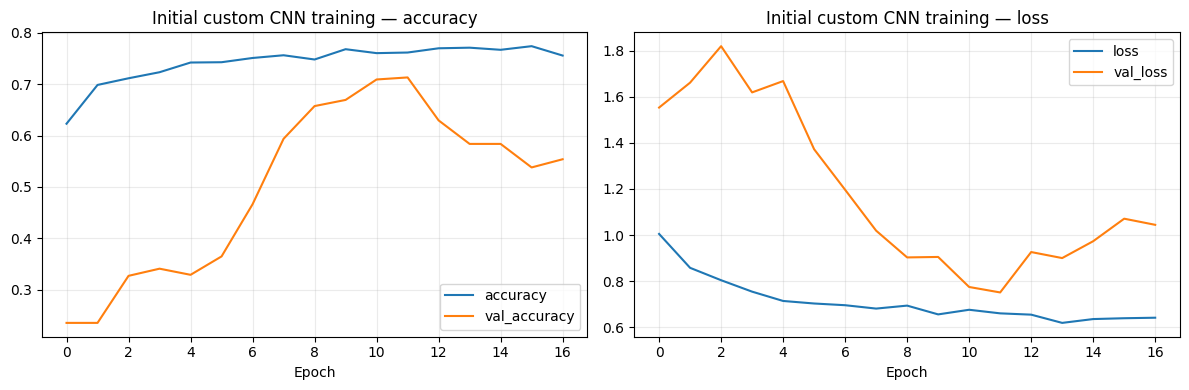

In [12]:
def plot_history(history, title):
    history_df = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    history_df[['accuracy', 'val_accuracy']].plot(ax=axes[0])
    history_df[['loss', 'val_loss']].plot(ax=axes[1])
    axes[0].set(title=f'{title} — accuracy', xlabel='Epoch')
    axes[1].set(title=f'{title} — loss', xlabel='Epoch')
    for ax in axes:
        ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

plot_history(initial_history, 'Initial custom CNN training')


{'val_loss': 0.7509485483169556, 'val_accuracy': 0.7131474018096924, 'val_macro_f1': 0.6917530033149579}
              precision    recall  f1-score   support

      Glioma      0.883     0.845     0.863       161
  Meningioma      0.761     0.411     0.534       124
    No Tumor      0.873     0.556     0.679        99
   Pituitary      0.532     0.983     0.690       118

    accuracy                          0.713       502
   macro avg      0.762     0.699     0.692       502
weighted avg      0.769     0.713     0.705       502



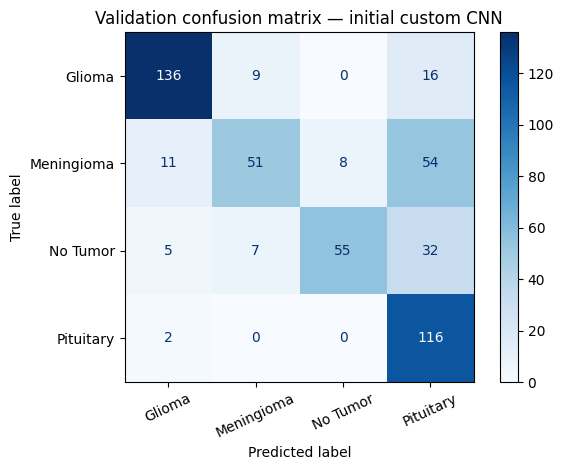

In [13]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

def predict_dataset(model_to_evaluate, dataset):
    probabilities = model_to_evaluate.predict(dataset, verbose=0)
    y_true = np.concatenate([labels.numpy() for _, labels in dataset])
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

def validation_summary(model_to_evaluate, dataset):
    loss, accuracy = model_to_evaluate.evaluate(dataset, verbose=0)
    y_true, y_pred, probabilities = predict_dataset(model_to_evaluate, dataset)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    return {'val_loss': float(loss), 'val_accuracy': float(accuracy),
            'val_macro_f1': float(macro_f1), 'y_true': y_true, 'y_pred': y_pred,
            'probabilities': probabilities}

initial_validation = validation_summary(initial_model, valid_ds)
print({key: value for key, value in initial_validation.items()
       if key in ['val_loss', 'val_accuracy', 'val_macro_f1']})
print(classification_report(
    initial_validation['y_true'], initial_validation['y_pred'],
    labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES, digits=3, zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    initial_validation['y_true'], initial_validation['y_pred'],
    labels=np.arange(NUM_CLASSES), display_labels=CLASS_NAMES, cmap='Blues',
    values_format='d', xticks_rotation=25,
)
plt.title('Validation confusion matrix — initial custom CNN')
plt.tight_layout()
plt.show()


## Step 7 — Continue training at a lower learning rate

A custom CNN has no pretrained backbone to unfreeze. Here, “fine-tuning” means continuing from the best validation checkpoint with a smaller learning rate. Validation data still guides this step. We will keep the checkpoint with lower validation loss from the initial and continued-training runs.

If you decide not to continue training, set `RUN_CONTINUED_TRAINING` to `False`; the initial best checkpoint will then be selected.


In [ ]:
RUN_CONTINUED_TRAINING = True

if RUN_CONTINUED_TRAINING:
    continued_model = tf.keras.models.load_model(initial_checkpoint)
    continued_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='sparse_categorical_crossentropy', metrics=['accuracy'],
    )
    continued_checkpoint = MODEL_DIR / 'custom_cnn_continued_best_validation.keras'
    continued_callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            continued_checkpoint, monitor='val_loss', mode='min', save_best_only=True, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', mode='min', patience=3, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', mode='min', factor=0.3, patience=2, min_lr=1e-7, verbose=1
        ),
    ]
    continued_history = continued_model.fit(
        train_ds, validation_data=valid_ds, epochs=FINE_TUNE_EPOCHS,
        class_weight=class_weights, callbacks=continued_callbacks,
    )
    continued_model = tf.keras.models.load_model(continued_checkpoint)
    plot_history(continued_history, 'Continued custom CNN training')
    continued_validation = validation_summary(continued_model, valid_ds)
    candidates = [
        ('initial', initial_model, initial_checkpoint, initial_validation),
        ('continued', continued_model, continued_checkpoint, continued_validation),
    ]
else:
    candidates = [('initial', initial_model, initial_checkpoint, initial_validation)]

for name, _, path, metrics in candidates:
    print(name, 'checkpoint:', path.name,
          '| validation loss:', round(metrics['val_loss'], 4),
          '| validation accuracy:', round(metrics['val_accuracy'], 4),
          '| validation macro-F1:', round(metrics['val_macro_f1'], 4))

best_run, selected_model, selected_checkpoint, selected_validation = min(
    candidates, key=lambda item: item[3]['val_loss']
)
print(f'\nSelected using lowest validation loss: {best_run} ({selected_checkpoint.name})')


## Step 8 — Final evaluation on the held-out test split

All training and checkpoint selection are complete. Now we create the test input pipeline and evaluate the selected model once. Do not use these test results to change the model; doing so would turn the test set into another validation set.


In [ ]:
test_ds = make_dataset(test_df, training=False)
test_loss, test_accuracy = selected_model.evaluate(test_ds, verbose=1)
y_test, y_test_pred, test_probabilities = predict_dataset(selected_model, test_ds)
test_macro_f1 = f1_score(y_test, y_test_pred, average='macro', zero_division=0)

print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Test macro-F1: {test_macro_f1:.4f}')
print(classification_report(
    y_test, y_test_pred, labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES, digits=3, zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, labels=np.arange(NUM_CLASSES),
    display_labels=CLASS_NAMES, cmap='Blues', values_format='d', xticks_rotation=25,
)
plt.title('Final held-out test confusion matrix — custom CNN')
plt.tight_layout()
plt.show()


## Step 9 — Save the final model and summary

The final model is saved in Keras format. We also save the exact class order and a JSON summary of the configuration, validation-based selection, and final test metrics. The test metrics are for reporting; they are not fed back into training or model selection.


In [16]:
FINAL_MODEL_PATH = MODEL_DIR / 'brain_mri_custom_cnn_final.keras'
CLASS_NAMES_PATH = MODEL_DIR / 'class_names.json'
SUMMARY_PATH = MODEL_DIR / 'custom_cnn_evaluation_summary.json'

selected_model.save(FINAL_MODEL_PATH)
with open(CLASS_NAMES_PATH, 'w', encoding='utf-8') as file:
    json.dump(CLASS_NAMES, file, indent=2)

summary = {
    'model': 'custom_cnn',
    'selected_training_run': best_run,
    'selection_rule': 'lowest validation loss',
    'selected_checkpoint': selected_checkpoint.name,
    'image_size': list(IMAGE_SIZE),
    'batch_size': BATCH_SIZE,
    'initial_epochs_requested': EPOCHS,
    'continued_training_epochs_requested': FINE_TUNE_EPOCHS if RUN_CONTINUED_TRAINING else 0,
    'seed': SEED,
    'class_names_in_output_order': CLASS_NAMES,
    'validation_loss': selected_validation['val_loss'],
    'validation_accuracy': selected_validation['val_accuracy'],
    'validation_macro_f1': selected_validation['val_macro_f1'],
    'test_loss': float(test_loss),
    'test_accuracy': float(test_accuracy),
    'test_macro_f1': float(test_macro_f1),
}
with open(SUMMARY_PATH, 'w', encoding='utf-8') as file:
    json.dump(summary, file, indent=2)

print('Final model:', FINAL_MODEL_PATH)
print('Class order:', CLASS_NAMES_PATH)
print('Metrics and configuration:', SUMMARY_PATH)


Final model: /content/drive/MyDrive/Brain MRI Tumor Classification/Models/brain_mri_custom_cnn_final.keras
Class order: /content/drive/MyDrive/Brain MRI Tumor Classification/Models/class_names.json
Metrics and configuration: /content/drive/MyDrive/Brain MRI Tumor Classification/Models/custom_cnn_evaluation_summary.json


## Notebook 2 complete

The custom CNN has now been trained, selected using validation loss, evaluated on the held-out test split, and saved under `models/`. Notebook 3 can train two pretrained CNNs using the same train/validation/test discipline. Notebook 4 can compare the three model families using validation results for selection and report final test results consistently.
